# Complex vs. Simplified Model
Is the bigger model worth it? Compare two CNNs on CIFAR-10 on **both** quality (accuracy) and cost
(parameters, file size, inference latency, training time).

In [1]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

keras.utils.set_random_seed(42)

# Original complex model
def create_complex_model(input_shape):
    model = keras.Sequential([keras.Input(shape=input_shape)])
    model.add(layers.Conv2D(32, (3, 3), activation='relu'))
    model.add(layers.MaxPooling2D((2, 2)))
    model.add(layers.Conv2D(64, (3, 3), activation='relu'))
    model.add(layers.MaxPooling2D((2, 2)))
    model.add(layers.Conv2D(128, (3, 3), activation='relu'))  # Added more layers
    model.add(layers.MaxPooling2D((2, 2)))
    model.add(layers.Flatten())
    model.add(layers.Dense(512, activation='relu'))  # Increased dense layer size
    model.add(layers.Dropout(0.5))  # Added dropout
    model.add(layers.Dense(10, activation='softmax'))
    return model

# Simplified model
def create_simplified_model(input_shape):
    model = keras.Sequential([keras.Input(shape=input_shape)])
    model.add(layers.Conv2D(32, (3, 3), activation='relu'))
    model.add(layers.MaxPooling2D((2, 2)))
    model.add(layers.Conv2D(64, (3, 3), activation='relu'))
    model.add(layers.MaxPooling2D((2, 2)))
    model.add(layers.Flatten())
    model.add(layers.Dense(128, activation='relu'))  # Reduced dense layer size
    model.add(layers.Dense(10, activation='softmax'))
    return model

In [2]:
(x_train, y_train), (x_test, y_test) = keras.datasets.cifar10.load_data()

# Scale pixels from 0-255 to 0-1; unscaled inputs make training unstable (huge initial loss)
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0
input_shape = x_train.shape[1:]

complex_model = create_complex_model(input_shape)
simplified_model = create_simplified_model(input_shape)

for model in (complex_model, simplified_model):
    model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

print(f"Complex model parameters:    {complex_model.count_params():,}")
print(f"Simplified model parameters: {simplified_model.count_params():,}")

Complex model parameters:    361,034
Simplified model parameters: 315,722


In [3]:
import time

# Train both models the same way (a few epochs for demonstration).
# Validate on a held-out slice of the training data - the test set is kept for the final comparison only.
epochs = 5
train_seconds = {}
histories = {}
for name, model in [("complex", complex_model), ("simplified", simplified_model)]:
    print(f"Training {name} model:")
    start = time.perf_counter()
    histories[name] = model.fit(x_train, y_train, epochs=epochs, batch_size=64, validation_split=0.1, verbose=2)
    train_seconds[name] = time.perf_counter() - start

Training complex model:


Epoch 1/5


704/704 - 12s - 17ms/step - accuracy: 0.4108 - loss: 1.5948 - val_accuracy: 0.5166 - val_loss: 1.3101


Epoch 2/5


704/704 - 11s - 15ms/step - accuracy: 0.5650 - loss: 1.2218 - val_accuracy: 0.6078 - val_loss: 1.0967


Epoch 3/5


... (12 outputs left out)

Epoch 4/5


704/704 - 10s - 14ms/step - accuracy: 0.6834 - loss: 0.9142 - val_accuracy: 0.6802 - val_loss: 0.9227


Epoch 5/5


704/704 - 9s - 13ms/step - accuracy: 0.7119 - loss: 0.8386 - val_accuracy: 0.6898 - val_loss: 0.9015


In [4]:
import os
import time
import tempfile
import numpy as np
import pandas as pd

def model_report(name, model, x_test, y_test, train_seconds):
    """Accuracy, size and speed for a trained Keras model."""
    loss, accuracy = model.evaluate(x_test, y_test, verbose=0)
    path = os.path.join(tempfile.mkdtemp(), "model.keras")
    model.save(path)
    single = x_test[:1]
    model.predict(single, verbose=0)  # warm-up
    start = time.perf_counter()
    for _ in range(50):
        model(single, training=False)
    single_ms = (time.perf_counter() - start) / 50 * 1e3
    start = time.perf_counter()
    model.predict(x_test, batch_size=256, verbose=0)
    throughput = len(x_test) / (time.perf_counter() - start)
    return {"model": name, "params": model.count_params(), "size_MB": os.path.getsize(path) / 1e6,
            "test_accuracy": accuracy, "test_loss": loss, "train_time_s": train_seconds,
            "latency_1_image_ms": single_ms, "throughput_img_per_s": throughput}

results = pd.DataFrame([
    model_report("complex", complex_model, x_test, y_test, train_seconds["complex"]),
    model_report("simplified", simplified_model, x_test, y_test, train_seconds["simplified"]),
]).set_index("model")

ratio = results.loc["complex"] / results.loc["simplified"]
print(f"Complex / simplified: {ratio['params']:.2f}x params, {ratio['size_MB']:.2f}x size, "
      f"{ratio['latency_1_image_ms']:.2f}x latency, accuracy difference "
      f"{results.loc['complex', 'test_accuracy'] - results.loc['simplified', 'test_accuracy']:+.3f}")
results.round(3)

Complex / simplified: 1.14x params, 1.14x size, 1.37x latency, accuracy difference +0.004


,params,size_MB,test_accuracy,test_loss,train_time_s,latency_1_image_ms,throughput_img_per_s
model,,,,,,,
complex,361034,4.380,0.685,0.899,54.905,6.711,15235.950
simplified,315722,3.826,0.681,0.935,49.271,4.889,13049.066


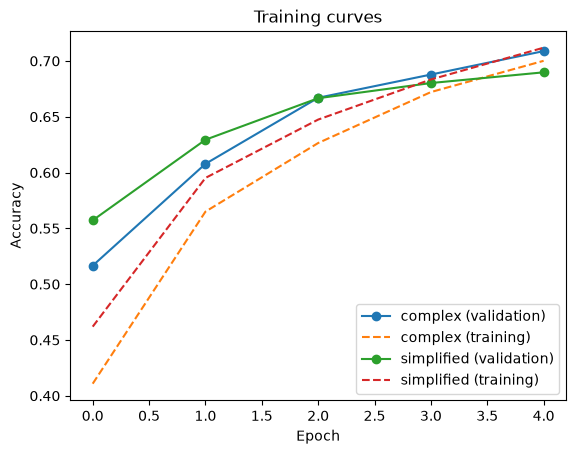

In [5]:
import matplotlib.pyplot as plt

for name, history in histories.items():
    plt.plot(history.history['val_accuracy'], 'o-', label=f'{name} (validation)')
    plt.plot(history.history['accuracy'], '--', label=f'{name} (training)')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Training curves')
plt.legend()
plt.show()

## Interpreting the comparison
* "Complex" is not automatically "bigger": the simplified model drops a conv/pool stage, so its `Flatten` layer
  feeds a much larger vector into `Dense` - check `count_params()` rather than counting layers.
* A training gap (training accuracy well above validation) signals overfitting; dropout in the complex model narrows it.
* The right choice depends on the deployment budget: if the smaller/faster model is within your accuracy tolerance, it wins.
* See `7B_W_SimpleDeepReduction.ipynb` for systematic ways to shrink a CNN.